In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatchesy
import seaborn as sns
import geopandas as gpd
import pandas as pd

In [5]:
df_station_details = pd.read_csv("/home/khanalp/code/PhD/daytoday/figures/EBR/station_details_final.csv", index_col=0)

In [6]:
df_station_details

,station,latitude (degree),longitude (degree),elevation (m),start year,end year,number of years,canopy height (m),measurement height (m),IGBP landcover type
8,SE-Htm,56.098,13.419,115.00,2018,2020,3,19.00,27.00,ENF
15,CZ-BK1,49.502,18.537,881.00,2023,2023,1,17.00,25.00,ENF
12,FR-FBn,43.241,5.679,436.00,2023,2024,2,10.00,17.00,ENF
11,FI-Sod,67.362,26.639,187.00,2023,2024,2,12.70,26.00,ENF
16,DE-Msr,47.809,11.456,602.07,2023,2023,1,2.00,4.23,ENF
7,FI-Hyy,61.847,24.295,181.00,2022,2024,3,17.00,27.00,ENF
17,IT-SR2,43.732,10.291,4.00,2020,2020,1,19.00,24.30,ENF
5,FR-Bil,44.494,-0.956,39.18,2021,2024,4,7.20,15.00,ENF
4,DE-Tha,50.963,13.565,380.00,2021,2024,4,29.40,42.00,ENF
3,SE-Svb,64.256,19.774,267.00,2019,2024,6,20.00,32.50,ENF


In [7]:
world = gpd.read_file("https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_50m_admin_0_countries.geojson")

In [8]:
europe = world[world["continent"] == "Europe"]

In [9]:
europe

,scalerank,labelrank,sovereignt,sov_a3,adm0_dif,level,type,admin,adm0_a3,geou_dif,...,region_un,subregion,region_wb,name_len,long_len,abbrev_len,tiny,homepart,featureclass,geometry
4,1,6,Albania,ALB,0,2,Sovereign country,Albania,ALB,0,...,Europe,Southern Europe,Europe & Central Asia,7,7,4,-99,1,Admin-0 country,"POLYGON ((20.06396 42.54727, 20.10352 42.52466..."
5,3,6,Finland,FI1,1,2,Country,Aland,ALD,0,...,Europe,Northern Europe,Europe & Central Asia,5,13,5,5,-99,Admin-0 country,"MULTIPOLYGON (((20.61133 60.04067, 20.60342 60..."
6,3,6,Andorra,AND,0,2,Sovereign country,Andorra,AND,0,...,Europe,Southern Europe,Europe & Central Asia,7,7,4,5,1,Admin-0 country,"POLYGON ((1.70605 42.50332, 1.67852 42.49668, ..."
16,1,4,Austria,AUT,0,2,Sovereign country,Austria,AUT,0,...,Europe,Western Europe,Europe & Central Asia,7,7,5,-99,1,Admin-0 country,"POLYGON ((16.95312 48.59883, 16.94883 48.58857..."
19,1,2,Belgium,BEL,0,2,Sovereign country,Belgium,BEL,0,...,Europe,Western Europe,Europe & Central Asia,7,7,5,-99,1,Admin-0 country,"POLYGON ((4.81602 51.43281, 4.8207 51.41206, 4..."
23,1,4,Bulgaria,BGR,0,2,Sovereign country,Bulgaria,BGR,0,...,Europe,Eastern Europe,Europe & Central Asia,8,8,5,-99,1,Admin-0 country,"POLYGON ((28.58535 43.74224, 28.56182 43.50132..."
26,1,5,Bosnia and Herzegovina,BIH,0,2,Sovereign country,Bosnia and Herzegovina,BIH,0,...,Europe,Southern Europe,Europe & Central Asia,16,22,4,-99,1,Admin-0 country,"POLYGON ((16.91865 45.27656, 17.12539 45.17178..."
28,1,4,Belarus,BLR,0,2,Sovereign country,Belarus,BLR,0,...,Europe,Eastern Europe,Europe & Central Asia,7,7,5,-99,1,Admin-0 country,"POLYGON ((28.14795 56.14292, 28.28428 56.05591..."
39,1,4,Switzerland,CHE,0,2,Sovereign country,Switzerland,CHE,0,...,Europe,Western Europe,Europe & Central Asia,11,11,6,-99,1,Admin-0 country,"POLYGON ((9.52402 47.52422, 9.55439 47.51113, ..."
56,1,5,Czech Republic,CZE,0,2,Sovereign country,Czech Republic,CZE,0,...,Europe,Eastern Europe,Europe & Central Asia,10,14,8,-99,1,Admin-0 country,"POLYGON ((14.80938 50.85898, 14.8958 50.86138,..."


In [10]:
# Filter for European countries (you can fine-tune this as needed)
europe = world[world['continent'] == 'Europe']


In [13]:
df_station_details_selected = df_station_details[df_station_details["IGBP landcover type"].isin(["ENF", "GRA"])]

In [14]:
df_station_details_selected.shape

(18, 10)

In [15]:
# Dissolve borders of European countries into a single geometry (mainland Europe)
europe_union = europe.dissolve()


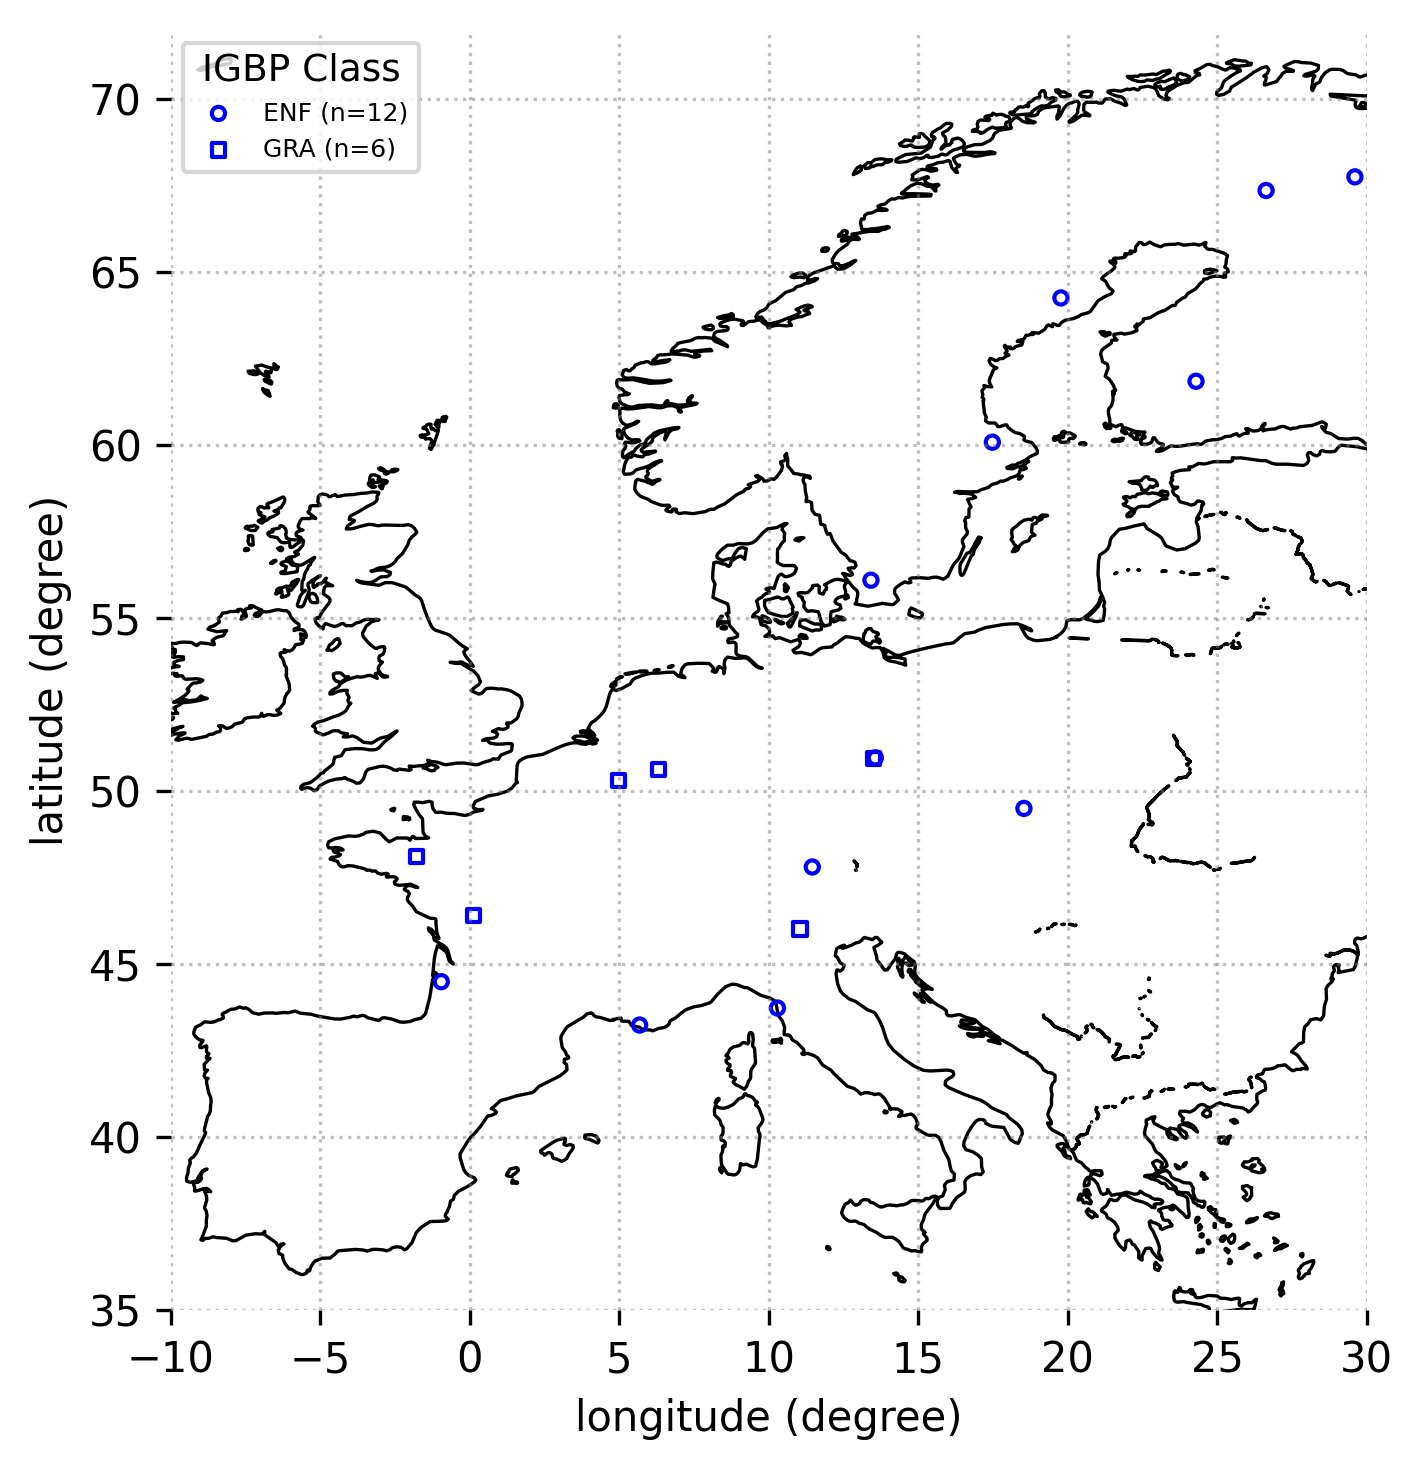

In [18]:
plt.rcParams['font.family'] = 'sans-serif'  # or 'sans-serif'

igbp_types = df_station_details_selected['IGBP landcover type'].unique()
marker_styles = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', 'h', '<', '>']
marker_map = dict(zip(igbp_types, marker_styles))

fig, ax = plt.subplots(figsize=(5, 5), dpi=300)

europe_union.plot(ax=ax, facecolor='white', edgecolor='black', linewidth=0.8, zorder=1)

for igbp, marker in marker_map.items():
    subset = df_station_details_selected[df_station_details_selected['IGBP landcover type'] == igbp]
    count = len(subset)
    ax.scatter(
        subset['longitude (degree)'],
        subset['latitude (degree)'],
        marker=marker,
        color='none',
        s=10,
        edgecolor='blue',
        zorder=1,
        label=f"{igbp} (n={count})"
    )

ax.set_xlim(-10, 30)
ax.set_ylim(35, 72)
ax.set_xticks(range(-10, 35, 5))
ax.set_yticks(range(35, 75, 5))
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True, labelsize=10)
ax.grid(True, linestyle=':', color='gray', alpha=0.5, zorder=0)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

ax.set_xlabel("longitude (degree)", fontsize=10)
ax.set_ylabel("latitude (degree)", fontsize=10)
ax.legend(title="IGBP Class", loc='upper left', fontsize=6, title_fontsize=9)

plt.tight_layout()
plt.show()
